# Benchmark Results

This notebook reproduces the benchmark figures from the paper. It evaluates three RL algorithms: **PPO**, **SAC**, **TD3** alongside three non-learning baselines: **FiPla**, **Constant**, **Random**  on the `survival-second-price-exponential` scenario (second-price auction, exponentially-distributed campaign horizon, survival value kernel).

See [`BENCHMARK.md`](BENCHMARK.md) for the full experimental protocol: scenario description, environment wrappers, training hyperparameters, and reproduction steps.

In [1]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd

## Shading α sweep

Grid search over the shading multiplier α (η = 50). Each α is evaluated over 30 seeds; we report mean ± std of total episode reward and the per-seed distribution.

In [7]:
shading_df = pd.read_csv(
    "benchmark_results/"
    "survival-second-price-exponential_eta50_shading_alpha_sweep_2026-04-29_23-36-59.csv"
)

# episode reward = last cum_reward value per (alpha, seed)
shading_summary = (
    shading_df.sort_values(["alpha", "seed", "step"])
    .groupby(["alpha", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

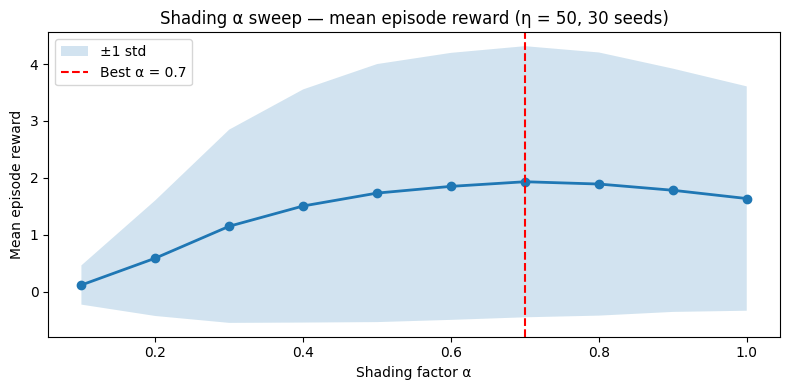

Best α = 0.7  (mean reward = 1.9320)


In [6]:
import matplotlib.pyplot as plt

mean_r = shading_summary.groupby("alpha")["episode_reward"].mean()
std_r  = shading_summary.groupby("alpha")["episode_reward"].std()
best_alpha = mean_r.idxmax()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha, color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (η = 50, 30 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_mean.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha:.4g}  (mean reward = {mean_r.max():.4f})")

/tmp/ipykernel_111389/441405177.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


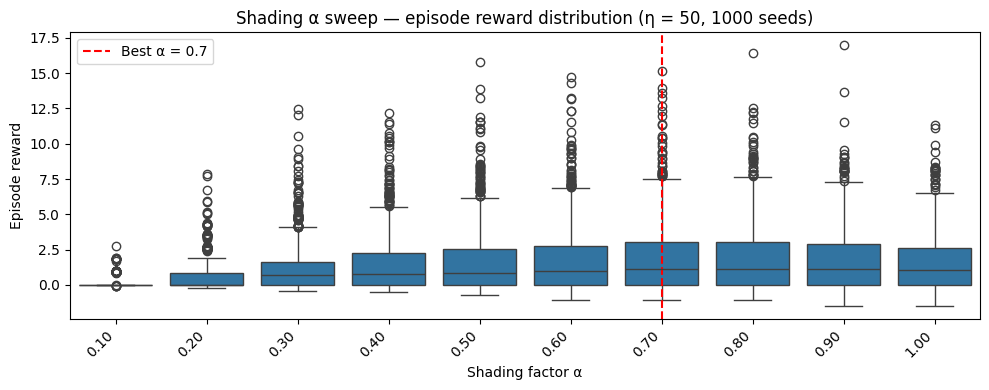

In [9]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=shading_summary, x="alpha", y="episode_reward",
    order=sorted(shading_summary["alpha"].unique()),
    ax=ax,
)
alphas_sorted = sorted(shading_summary["alpha"].unique())
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.axvline(alphas_sorted.index(best_alpha), color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_dist.pdf", bbox_inches="tight")
plt.show()

## 1. Run benchmark

Requires pretrained models in `benchmark/models/` (see `BENCHMARK.md § Pretrained Models`). Skip this cell and go to **Section 2** if you already have a saved CSV.

**If you haven't trained a MLPValuationHead yet, run first:**

```bash
python -m benchmark.train_mlp
```

Then run the evaluation (add `--sim-policies mpc` to include MPC, which takes a few extra minutes):

## 2. Load results

Load the saved per-step CSV and build the score matrix (total episode reward per policy per seed) used by rliable.

In [2]:
scenario_id = "survival-second-price-exponential"
date_time = "2026-04-28_16-14-27"
final_df = pd.read_csv(f"benchmark_results/survival-second-price-exponential_eta50_results.csv")

In [3]:
scores = score_matrix(final_df)

Mean number of auction opportunities per episode across all seeds. The horizon is exponentially distributed with rate η, giving a mean campaign length of 1/η auctions.

In [4]:
algos_list = final_df["policy"].unique()
algos_list

<StringArray>
[                  'FiPla',            'GreedyMyopic',
               'MPC(H=10)',               'MPC(H=25)',
 'MPCTimeBinned(H=10,K=2)',          'Shading(α=0.7)']
Length: 6, dtype: str

## 3. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 30 seeds, with stratified bootstrap confidence intervals (rliable). Lower variance in IQM makes it a more reliable aggregate than mean for small seed counts.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/aggregate_metrics.pdf


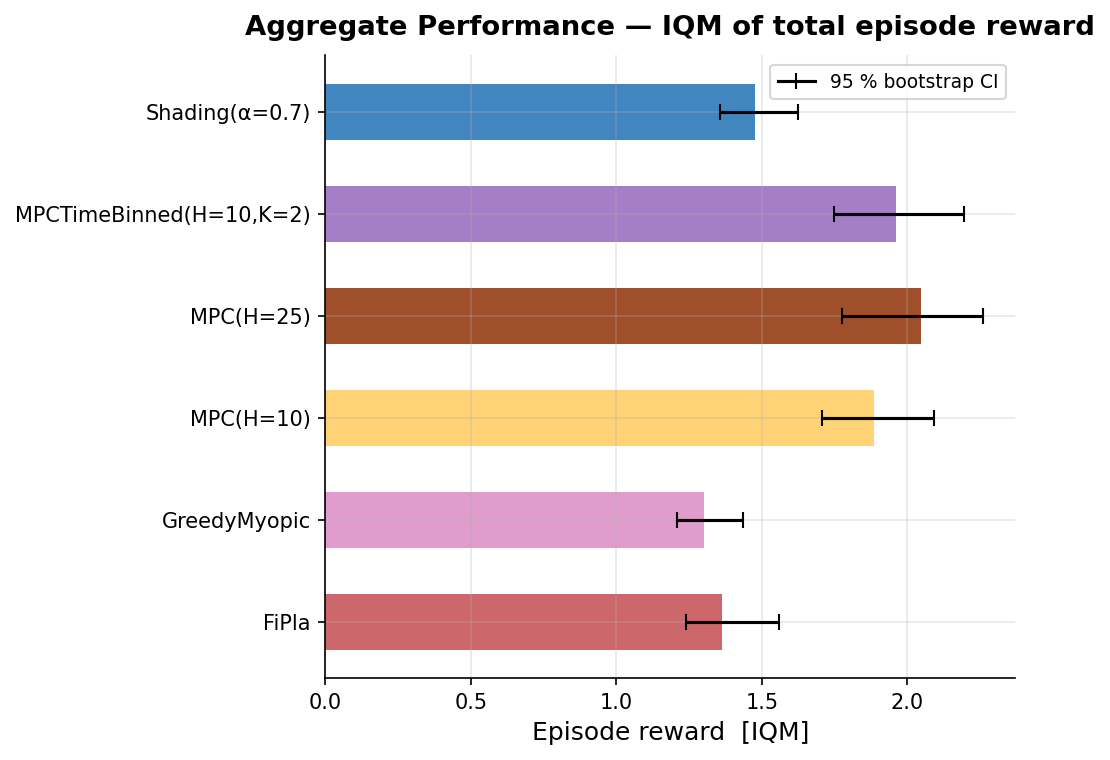

In [5]:
_ = plots.plot_aggregate_metrics(scores, metric="iqm", normalize_by=None)

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/performance_profiles.pdf


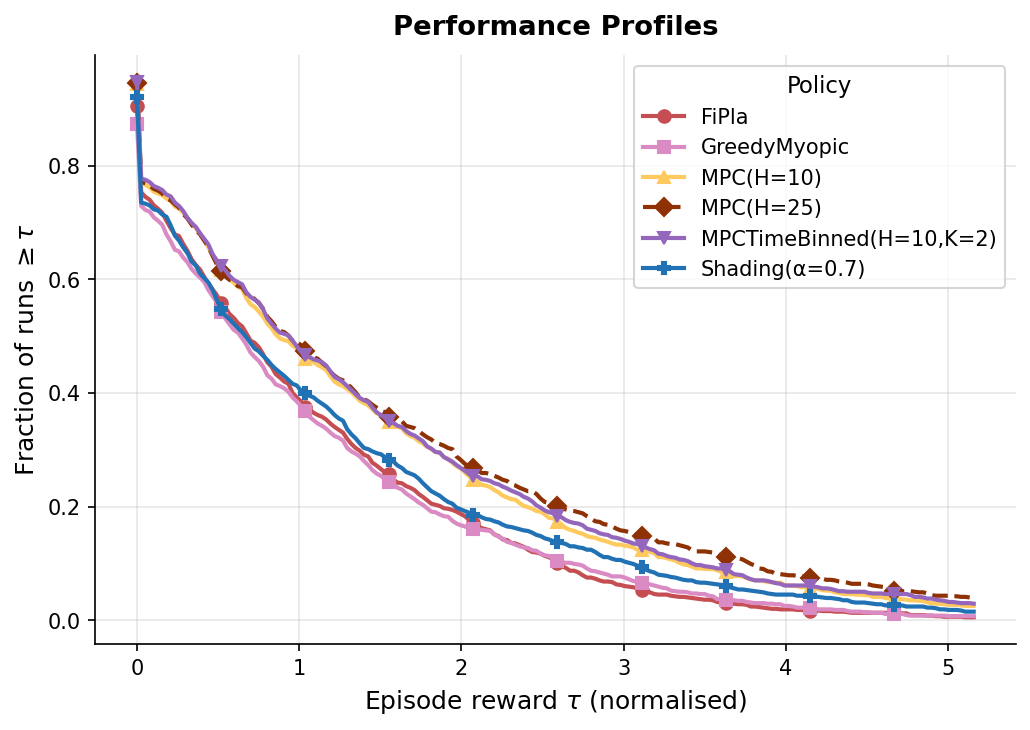

In [6]:
_ = plots.plot_performance_profiles(scores)

### Cumulative reward over time

Mean cumulative reward as a function of auction step, averaged over 30 seeds. Shaded bands are ±1 standard deviation.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/cumulative_reward.pdf


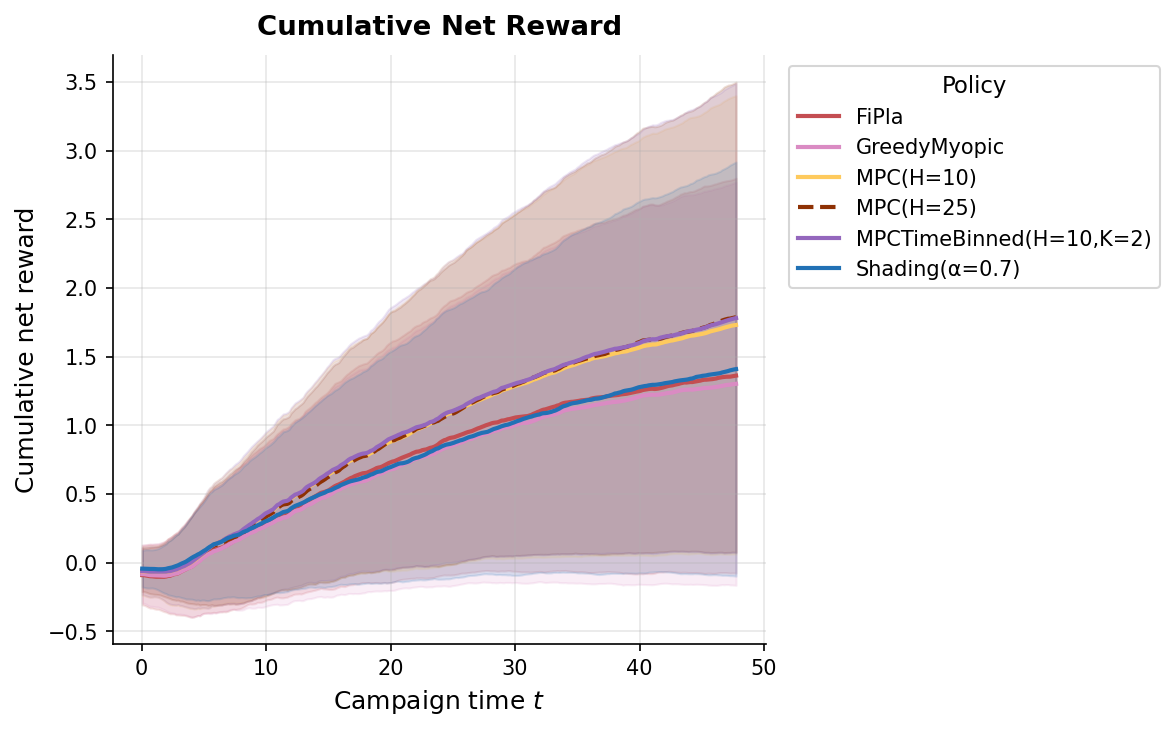

In [7]:
_ = plots.plot_cumulative_reward(final_df)

### Episode reward distribution

Distribution of total episode reward across 30 seeds for each policy (violin + individual seed points).

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:393: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:402: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/reward_distribution.pdf


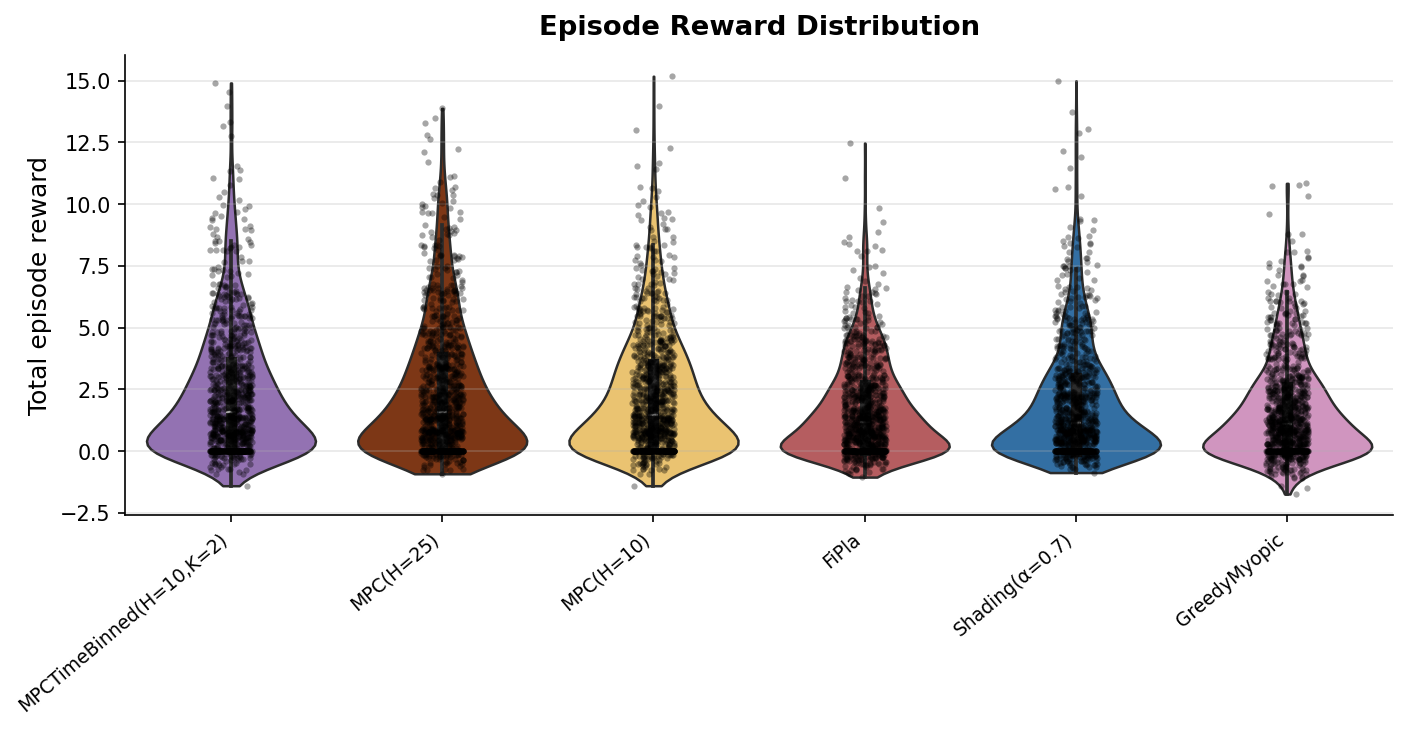

In [8]:
_ = plots.plot_reward_distribution(final_df)

### Training curves

Mean episodic reward during training (from TensorBoard logs), smoothed over a rolling window. One curve per RL algorithm; baselines are not trained so they do not appear here.

  [WARNING] Tag 'eval/mean_reward' not found for SAC
  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/training_curves.pdf


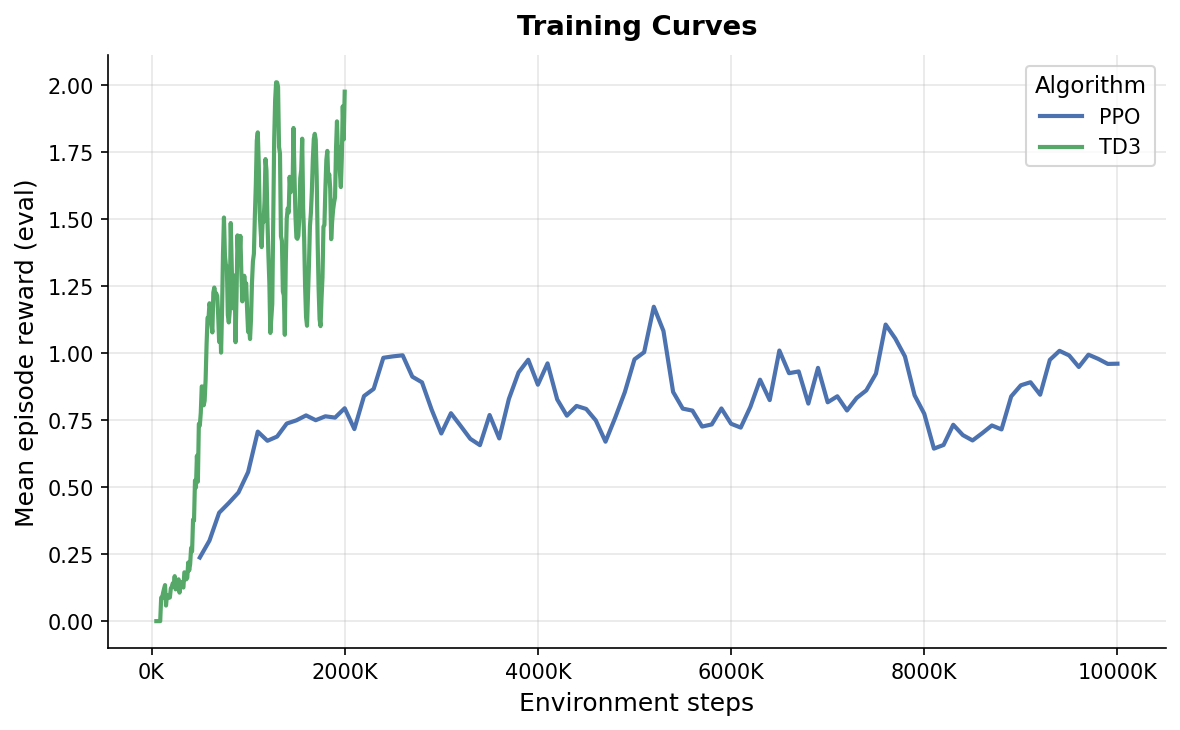

In [9]:
_ = plots.plot_training_curves()

### Context dynamics

Evolution of the context signal `ctx` over auction steps, averaged across seeds. Illustrates how the survival/saturation value kernel erodes the display value as the campaign progresses.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/context_dynamics.pdf


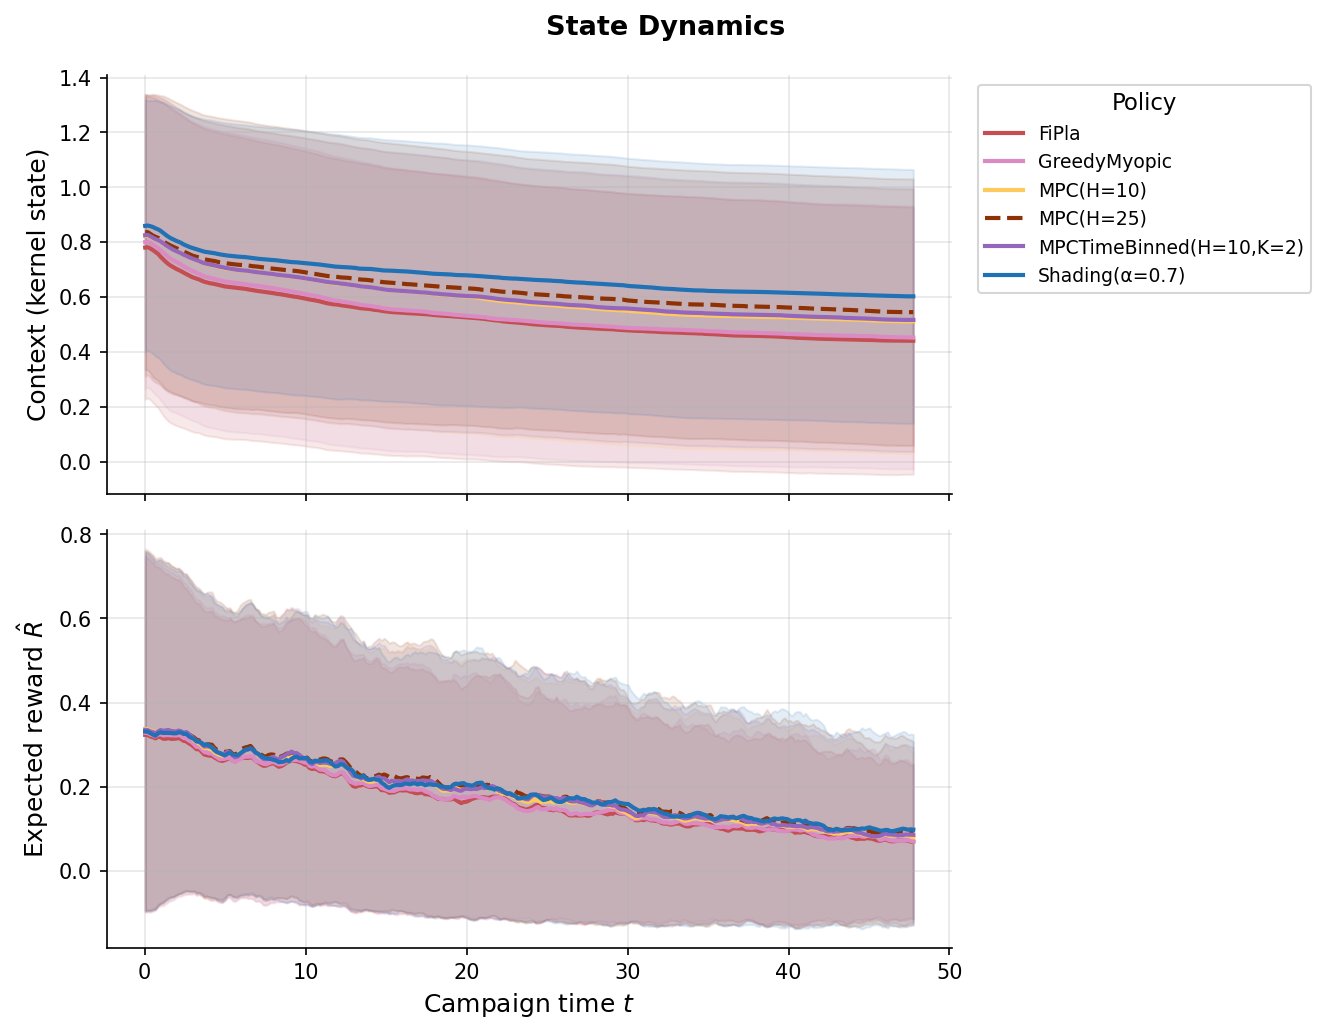

In [10]:
_ = plots.plot_context_dynamics(final_df)

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true value.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/bid_distributions.pdf


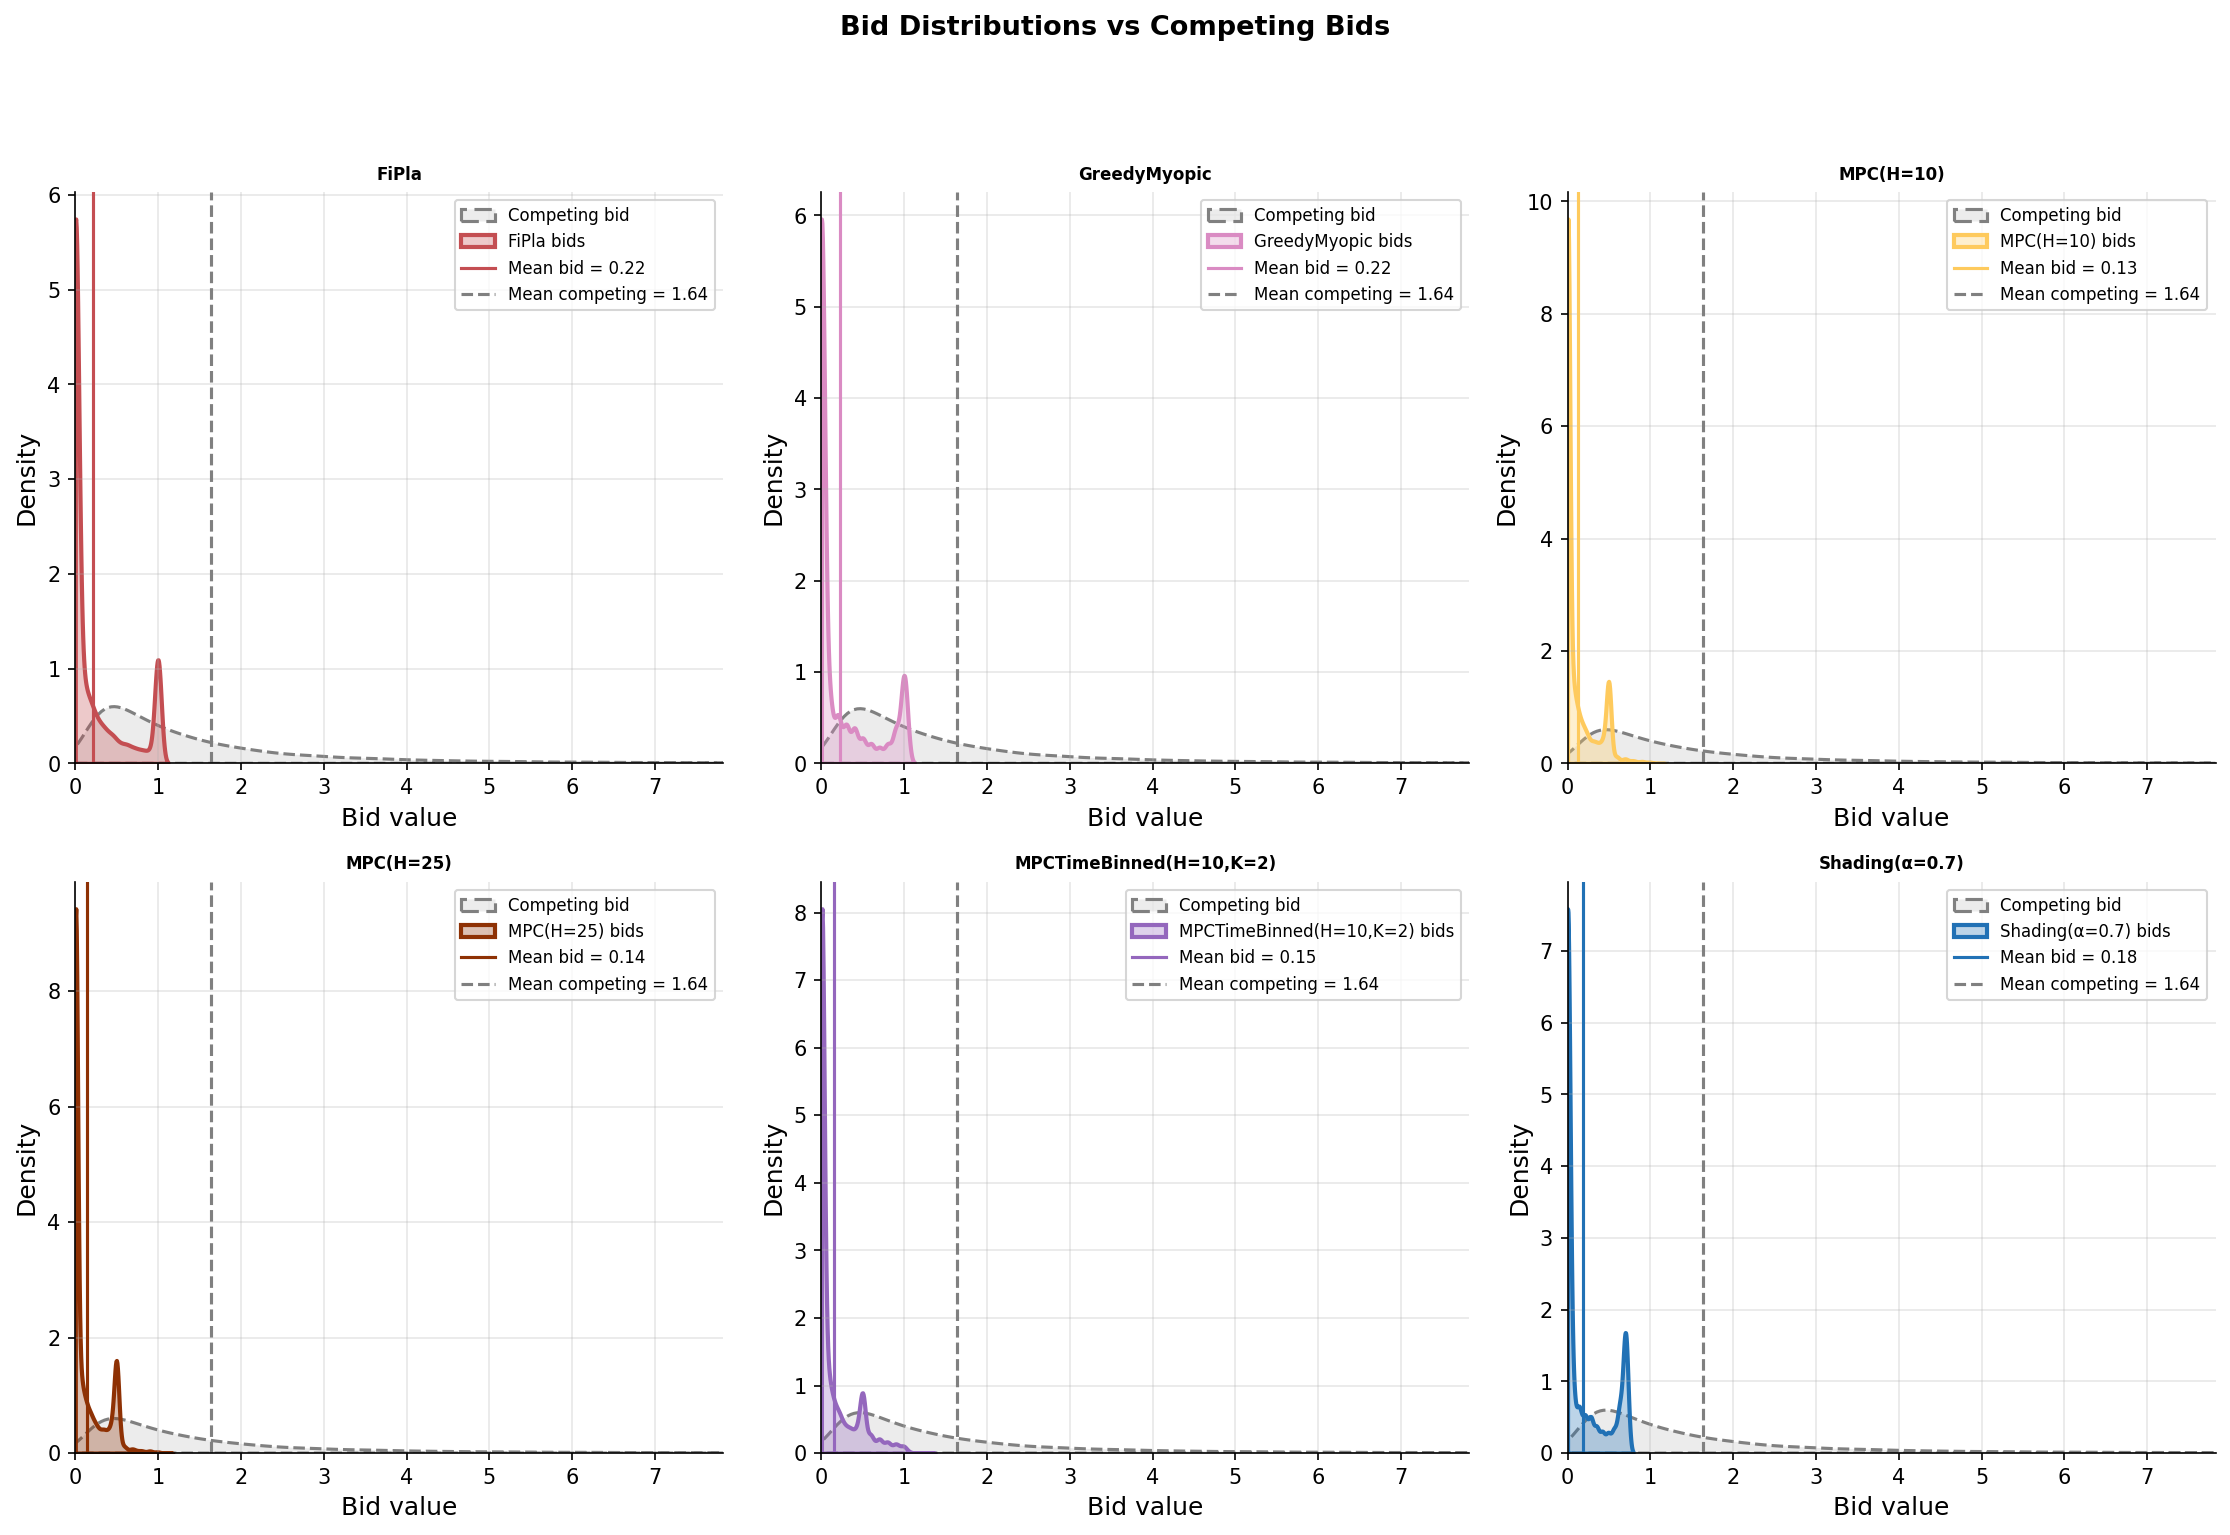

In [11]:
_ = plots.plot_bid_distributions(final_df)

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:626: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",
/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:633: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/win_rate.pdf


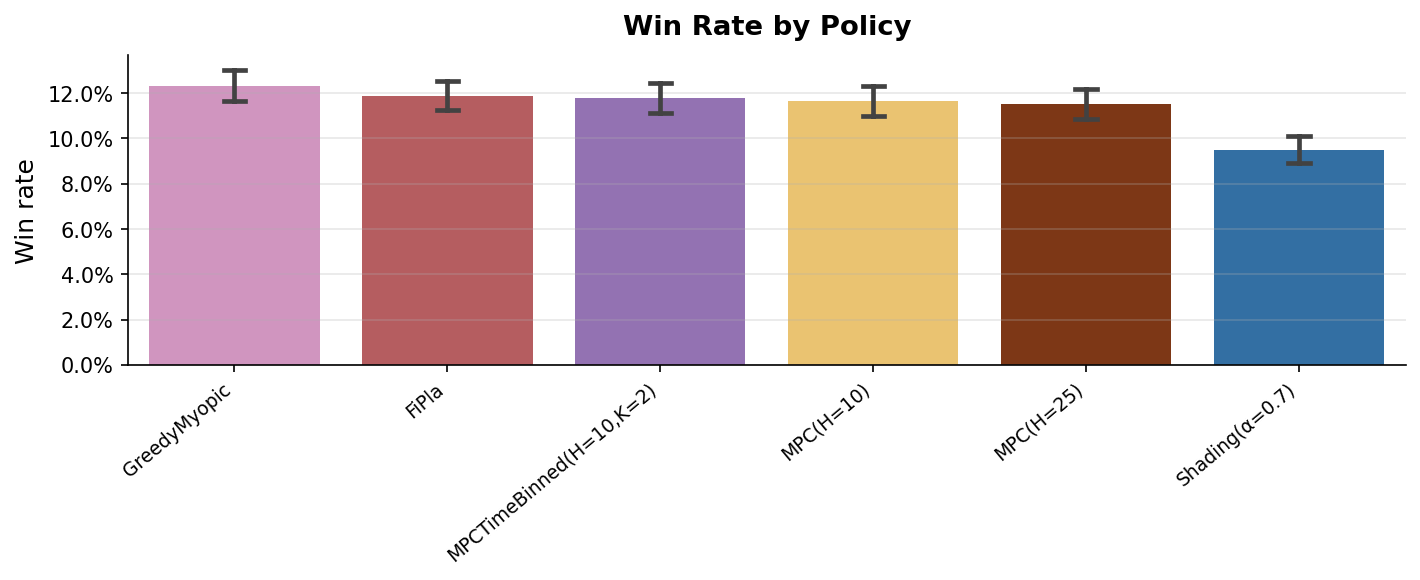

In [12]:
_ = plots.plot_win_rate(final_df)

### MPC's optimal alphas

At each auction step, MPC-family policies select the shading multiplier α* that maximises the estimated planning return over a rolling horizon. The distribution below shows which α* values are preferred across all steps and seeds — a concentration near high α values indicates the policy tends to bid aggressively, while a spread across the candidate set suggests the optimal multiplier is context-dependent.

In [ ]:
_ = plots.plot_mpc_alpha_chosen(final_df)

### Full benchmark summary

Combined figure reported in the paper, aggregating aggregate metrics, performance profiles, and reward distributions into a single panel.

/home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots.py:748: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/repeated-auction-dynamic-value/benchmark/plots/full_benchmark.pdf


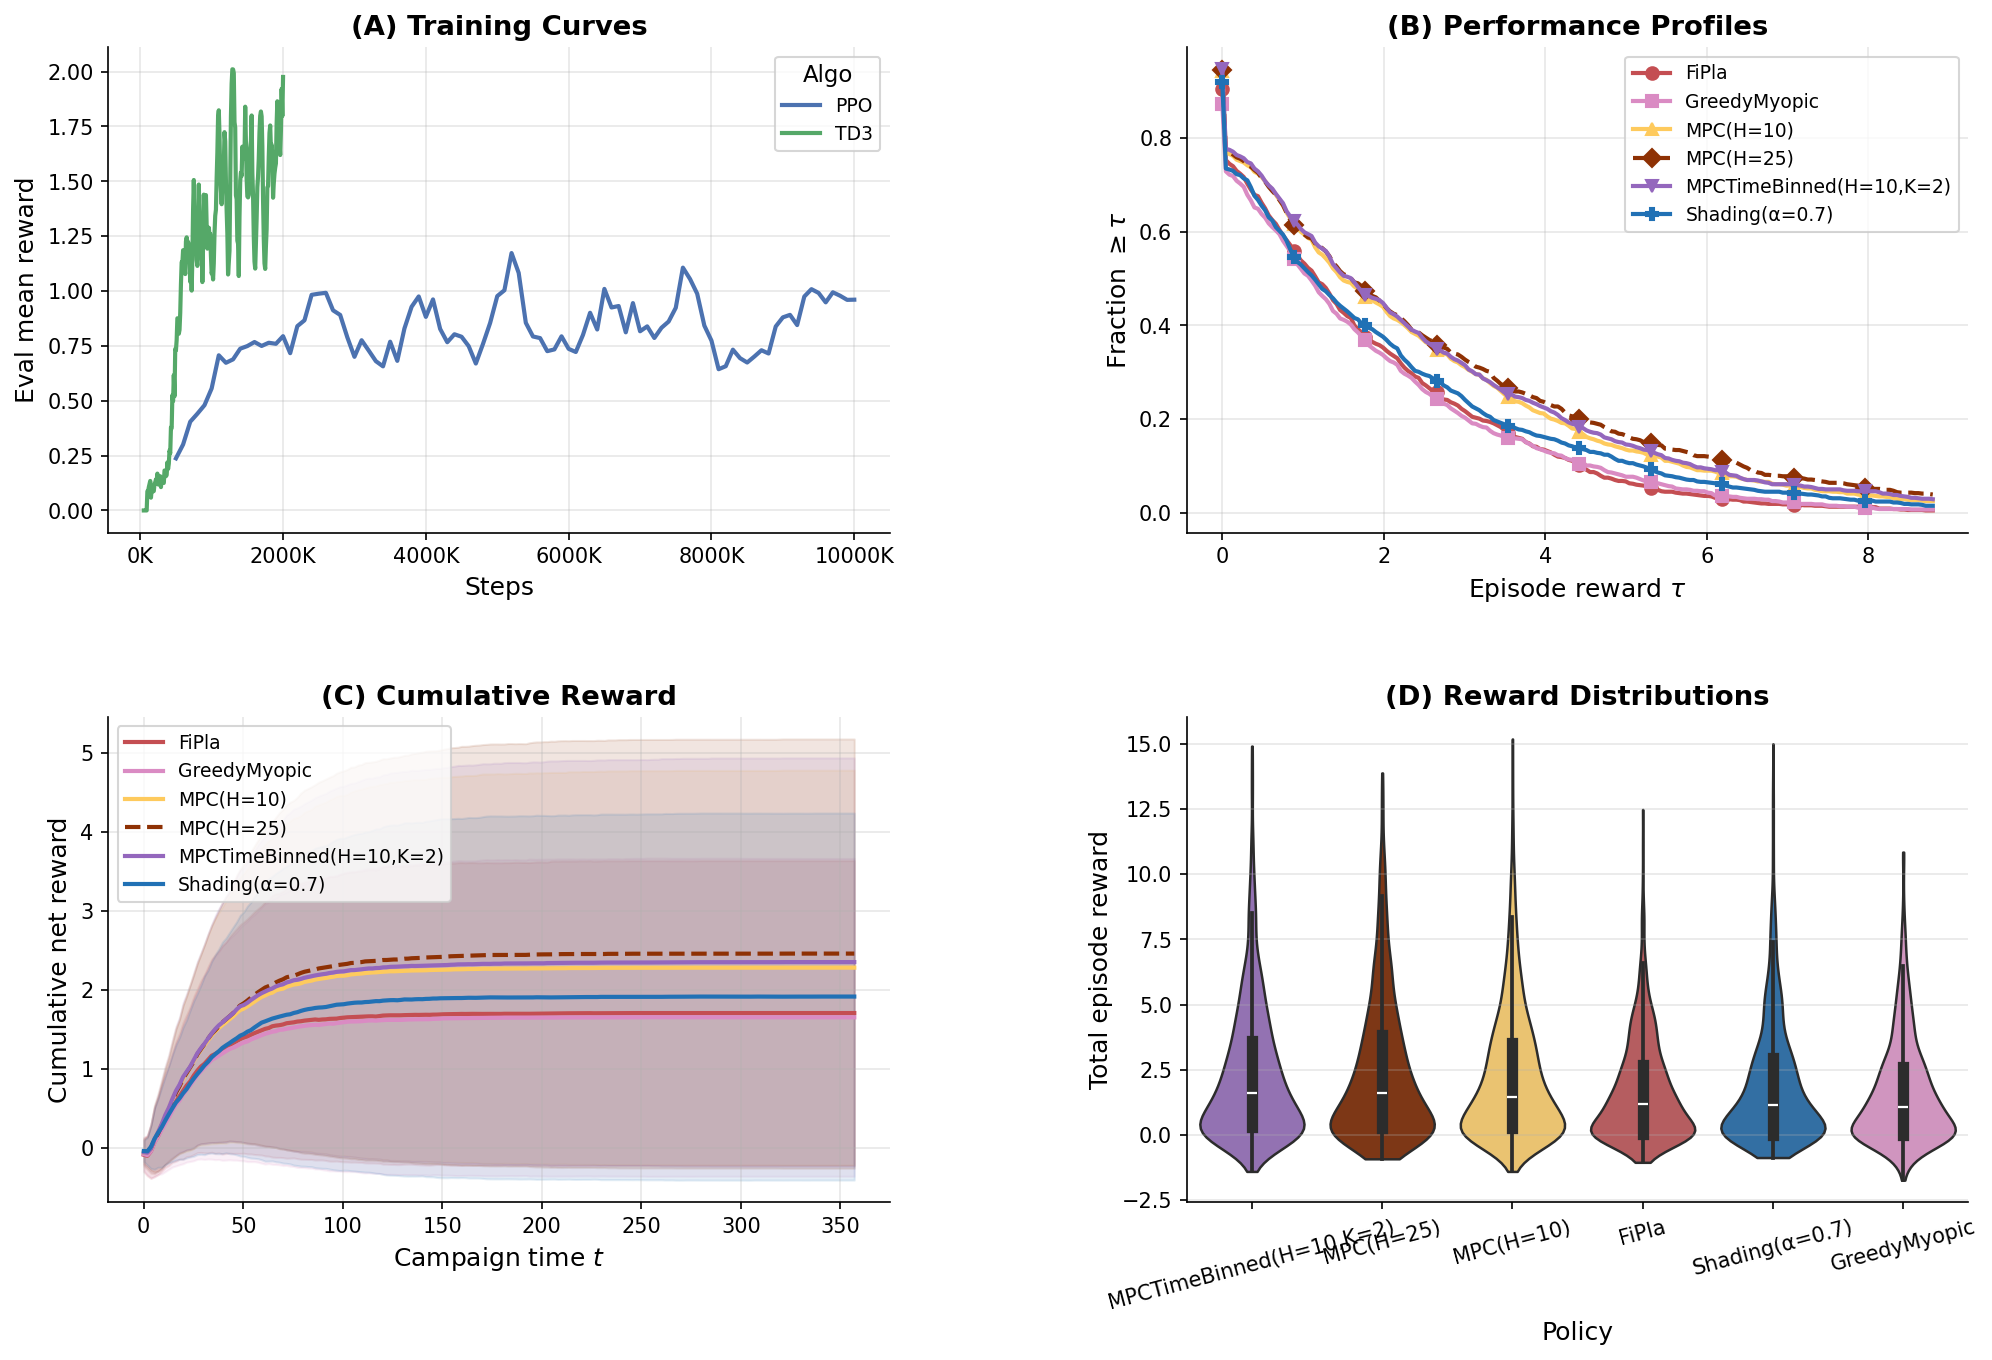

In [14]:
_ = plots.plot_full_benchmark(final_df, scores)